In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    mean_squared_error,
    r2_score,
    silhouette_score
)

# 1. Direct URL to Mall Customers Dataset
url = "https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv"
df = pd.read_csv(url)

# Rename Columns for clean ML access
df.rename(columns={
    'Annual Income (k$)': 'Annual_Income_k',
    'Spending Score (1-100)': 'Spending_Score'
}, inplace=True)

# Generate Target Variables for Supervised Learning Tasks
np.random.seed(42)

# Churn Target: High spending but older age / low visits tend to churn
df['Days_Since_Last_Purchase'] = np.random.randint(1, 300, len(df))
df['Support_Tickets'] = np.random.randint(0, 5, len(df))
df['Churn'] = np.where((df['Days_Since_Last_Purchase'] > 150) | (df['Support_Tickets'] >= 3), 1, 0)

# Future Spend Target: Realistic spending estimation
df['Future_Spend'] = (df['Annual_Income_k'] * 12) + (df['Spending_Score'] * 8) - (df['Support_Tickets'] * 15) + np.random.normal(0, 25, len(df))

print("Dataset Loaded & Enhanced Successfully!")
print(df.head())

Dataset Loaded & Enhanced Successfully!
   CustomerID  Gender  Age  Annual_Income_k  Spending_Score  \
0           1    Male   19               15              39   
1           2    Male   21               15              81   
2           3  Female   20               16               6   
3           4  Female   23               16              77   
4           5  Female   31               17              40   

   Days_Since_Last_Purchase  Support_Tickets  Churn  Future_Spend  
0                       103                2      0    448.268677  
1                       271                3      1    810.419906  
2                       107                2      0    262.827804  
3                        72                1      0    780.539834  
4                       189                2      1    485.890114  


--- Clustering Evaluation ---
Silhouette Score: 0.5547


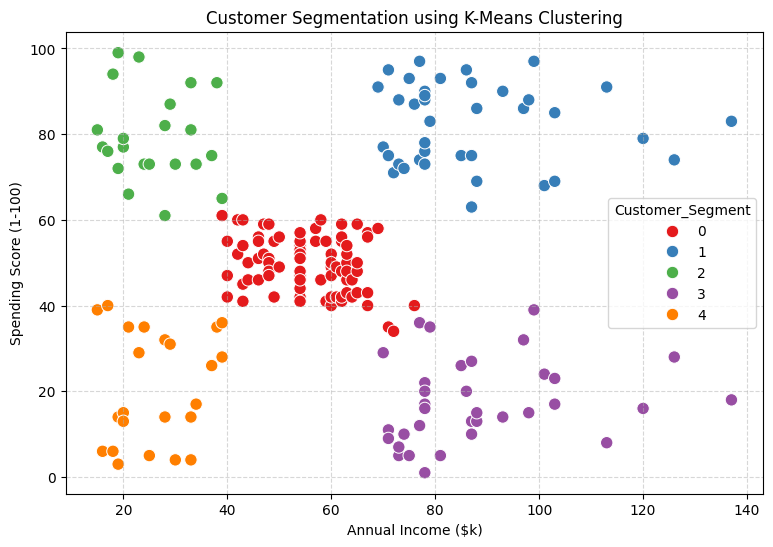

In [5]:
# Feature Selection for Clustering
X_cluster = df[['Annual_Income_k', 'Spending_Score']]

# Feature Scaling
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# K-Means Model Building (5 Clusters)
kmeans = KMeans(n_clusters=5, random_state=42)
df['Customer_Segment'] = kmeans.fit_predict(X_cluster_scaled)

sil_score = silhouette_score(X_cluster_scaled, df['Customer_Segment'])
print(f"--- Clustering Evaluation ---")
print(f"Silhouette Score: {sil_score:.4f}")

# Visualization
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Customer_Segment',
    data=df,
    palette='Set1',
    s=80
)
plt.title('Customer Segmentation using K-Means Clustering')
plt.xlabel('Annual Income ($k)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Feature Selection for Clustering
X_cluster = df[['Annual_Income_k', 'Spending_Score']]

# Feature Scaling
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# K-Means Model Building (5 Clusters)
kmeans = KMeans(n_clusters=5, random_state=42)
df['Customer_Segment'] = kmeans.fit_predict(X_cluster_scaled)

sil_score = silhouette_score(X_cluster_scaled, df['Customer_Segment'])
print(f"--- Clustering Evaluation ---")
print(f"Silhouette Score: {sil_score:.4f}")

# Visualization
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x='Annual_Income_k',
    y='Spending_Score',
    hue='Customer_Segment',
    data=df,
    palette='Set1',
    s=80
)
plt.title('Customer Segmentation using K-Means Clustering')
plt.xlabel('Annual Income ($k)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [6]:
# Features and Target
X_class = df[['Age', 'Annual_Income_k', 'Spending_Score', 'Days_Since_Last_Purchase', 'Support_Tickets']]
y_class = df['Churn']

# Train-Test Split
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

# Random Forest Classifier
clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train_c, y_train_c)

# Predictions & Metrics
y_pred_c = clf.predict(X_test_c)

print("--- Classification Results (Churn Prediction) ---")
print(f"Accuracy Score: {accuracy_score(y_test_c, y_pred_c):.4f}")
print("\nClassification Report:\n", classification_report(y_test_c, y_pred_c))

--- Classification Results (Churn Prediction) ---
Accuracy Score: 1.0000

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        11
           1       1.00      1.00      1.00        29

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



In [7]:
# Features and Target
X_reg = df[['Age', 'Annual_Income_k', 'Spending_Score', 'Support_Tickets']]
y_reg = df['Future_Spend']

# Train-Test Split
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Random Forest Regressor
reg = RandomForestRegressor(n_estimators=100, random_state=42)
reg.fit(X_train_r, y_train_r)

# Predictions & Metrics
y_pred_r = reg.predict(X_test_r)

rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
r2 = r2_score(y_test_r, y_pred_r)

print("--- Regression Results (Future Revenue Forecasting) ---")
print(f"R² Score: {r2:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

--- Regression Results (Future Revenue Forecasting) ---
R² Score: 0.9600
Root Mean Squared Error (RMSE): 52.7382
